# Preprocesamiento de Datos - Observatorio de Turismo de Colombia

Este notebook documenta y ejecuta el flujo completo de limpieza, estandarización, tratamiento de inconsistencias, ingeniería de variables y normalización de la **Tabla Maestra** del Observatorio Analítico del Turismo en Colombia.

---

## 1. Estandarización de Nombres y Columnas

### Diagnóstico y Corrección de Columnas
La tabla maestra original presenta ciertas inconsistencias en sus nombres que dificultan la codificación limpia:
- Espacios residuales al final de los nombres (ej. `'PIB '`).
- Caracteres especiales y asteriscos (ej. `'Transporte **'`).
- **Duplicidad de nombres base** resueltos automáticamente con sufijos genéricos por el merge (ej. `_x` y `_y`).

Para resolver esto de forma definitiva sin alterar los datos, renombramos las columnas usando prefijos semánticos:
- **`Ocupados_`**: Personas ocupadas en el sector (Fuente: GEIH, DANE).
- **`VA_`**: Valor agregado sectorial (PIB).
- **`Visit_`**: Conteo de visitantes y turistas.

También removemos los espacios en blanco residuales para asegurar llamadas de variables estables.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
# 1. Pegas la URL "Raw" que copiaste de GitHub
url_conexion = "https://github.com/hivalerieee/Observatorio-analitico-del-turismo-en-colombia/raw/refs/heads/main/Tabla_Maestra.xlsx"
# 2. Usamos read_excel para leer el archivo de Excel en memoria
df = pd.read_excel(url_conexion)


df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 44 columns):
 #   Column                                                              Non-Null Count  Dtype  
---  ------                                                              --------------  -----  
 0   Año                                                                 40 non-null     int64  
 1   Trimestre                                                           40 non-null     int64  
 2   region_Amazonía                                                     40 non-null     int64  
 3   region_Andina                                                       40 non-null     int64  
 4   region_Caribe                                                       40 non-null     int64  
 5   region_Insular                                                      40 non-null     int64  
 6   region_Orinoquía                                                    40 non-null     int64  
 7   region_Pacífica    

In [ ]:
RENOMBRAR = {
    "Ocupados Total Nacional": "Ocupados_Total",
    "Comercio y reparación de vehículos": "Ocupados_Comercio",
    "Alojamiento y servicios de comida_x": "Ocupados_Alojamiento_Comida",
    "Transporte y almacenamiento": "Ocupados_Transporte",
    "Comercio al por mayor y por menor*": "VA_Comercio",
    "Transporte **": "VA_Transporte",
    "Alojamiento y servicios de comida_y": "VA_Alojamiento_Comida",
    "Subtotal Valor Agregado": "VA_Subtotal",
    "Extranjeros no residentes sin venezolanos": "Visit_Extranjeros_sin_Venezuela",
    "Residentes en Venezuela por motivo de Descanso y Esparcimiento": "Visit_Residentes_Venezuela_Descanso",
    "Colombianos residentes exterior": "Visit_Colombianos_exterior",
    "Pasajeros en cruceros internacionales": "Visit_Cruceros",
    "Total visitantes no residentes": "Visit_Total",
}
df = df.copy()
df.columns = df.columns.str.strip().str.replace(r"\s+", " ", regex=True)
df = df.rename(columns=RENOMBRAR)
df = df.rename(columns={
    "Var. PIB respecto al mismo período del año anterior": "Var_PIB_anual",
    "Var. Aloj&Serv. Comida respecto al mismo período del año anterior.": "Var_Aloj_Comida_anual",
})
assert df.columns.is_unique

print(df.columns)

Index(['Año', 'Trimestre', 'region_Amazonía', 'region_Andina', 'region_Caribe',
       'region_Insular', 'region_Orinoquía', 'region_Pacífica',
       'region_Sin Especificar', 'motivo_Educación y formación',
       'motivo_Negocios y motivos profesionales', 'motivo_Otros motivos',
       'motivo_Religión y peregrinaciones', 'motivo_Salud y atención médica',
       'motivo_Tránsito', 'motivo_Vacaciones, recreo y ocio',
       'motivo_Visitas a familiares y amigos', 'sexo_Femenino',
       'sexo_Masculino', 'sexo_Otro', 'Ocupados_Total', 'Ocupados_Comercio',
       'Ocupados_Alojamiento_Comida', 'Ocupados_Transporte', 'TRM_promedio',
       'TRM_cierre', 'Visit_Extranjeros_sin_Venezuela',
       'Visit_Residentes_Venezuela_Descanso', 'Visit_Colombianos_exterior',
       'Visit_Cruceros', 'Visit_Total', 'VA_Comercio', 'VA_Transporte',
       'VA_Alojamiento_Comida', 'VA_Subtotal', 'PIB', 'Var_PIB_anual',
       'Var_Aloj_Comida_anual', 'Continente_América', 'Continente_Asia',
       'Con

## 2. Datos duplicados (verificación)

Revisa cuatro tipos de duplicado sobre `df`, sin modificarlo:
1. **Filas completamente repetidas** (`df.duplicated()`).
2. **Periodos repetidos**: la llave de la tabla es (`Año`, `Trimestre`); cada trimestre debe aparecer una sola vez.
3. **Huecos en la serie**: que los trimestres sean consecutivos, sin saltos.
4. **Columnas con contenido idéntico**: el `merge` de la hoja de PIB generó columnas `_x` / `_y`, así que se comprueba que no haya variables copiadas.

**Por qué.** Un trimestre duplicado se contaría doble en promedios, correlaciones y KPI; un hueco rompería las series de tiempo y las gráficas. Se hace **antes** de tratar los faltantes (Sección 4) porque rellenar con 0 puede crear filas o columnas que *parecen* duplicadas sin serlo.

**Qué concluimos.** Es una verificación, no una limpieza: no se elimina nada (la regla es no borrar filas). Si algún día aparece un duplicado, la celda lo muestra y se detiene para revisarlo a mano; no lo borra sola.

*Nota sobre columnas idénticas:* dos columnas llenas solo de ceros serían idénticas sin ser un error; por eso la prueba 4 ignora las columnas constantes y solo reporta.

In [ ]:
# Verificación de duplicados (no modifica df)
dup_filas = int(df.duplicated().sum())
dup_periodos = int(df.duplicated(subset=["Año", "Trimestre"]).sum())

# Trimestres consecutivos: Año*4 + Trimestre debe avanzar de 1 en 1
dup_orden = (df["Año"] * 4 + df["Trimestre"]).sort_values()
dup_huecos = int((dup_orden.diff().dropna() != 1).sum())

# Columnas idénticas (se ignoran las constantes, p. ej. todo ceros)
dup_no_const = df.loc[:, df.nunique(dropna=False) > 1]
dup_cols_iguales = dup_no_const.columns[dup_no_const.T.duplicated(keep=False)].tolist()

print(f"Filas duplicadas completas : {dup_filas}")
print(f"Periodos (Año, Trimestre) repetidos : {dup_periodos}")
print(f"Saltos en la secuencia de trimestres: {dup_huecos}")
print(f"Columnas con contenido idéntico     : {dup_cols_iguales if dup_cols_iguales else 'ninguna'}")
dup_ext = df.sort_values(["Año", "Trimestre"])[["Año", "Trimestre"]].iloc[[0, -1]].astype(int).values
print(f"Trimestres en la tabla: {len(df)} ({dup_ext[0][0]}-T{dup_ext[0][1]} a {dup_ext[1][0]}-T{dup_ext[1][1]})")

assert dup_filas == 0 and dup_periodos == 0, "Hay duplicados: revisar antes de continuar (no se borran solos)"
assert dup_huecos == 0, "Hay trimestres faltantes o saltos en la serie"
if dup_cols_iguales:
    print("AVISO: revisar si estas columnas son copia una de otra (no se borran):", dup_cols_iguales)

Filas duplicadas completas : 0
Periodos (Año, Trimestre) repetidos : 0
Saltos en la secuencia de trimestres: 0
Columnas con contenido idéntico     : ninguna
Trimestres en la tabla: 40 (2015-T1 a 2024-T4)


## 3. Categorización

 Primero se comprueba qué tipo de dato tiene cada columna de `df` y se clasifica cada variable por su **rol analítico** (identificador de tiempo, conteo de visitantes, ocupados, valor agregado, macroeconómica, variación). El resultado es un diccionario de variables.

**Por qué.** La categorización sirve para decidir qué técnica aplica a cada variable. Aquí hay un hallazgo: **la tabla no tiene columnas categóricas**, todas son numéricas. Las "categorías" (región, motivo, sexo, continente) ya vienen convertidas en una columna de conteo por categoría. Por eso **no hace falta codificar** (one-hot, label encoding) ni agrupar niveles raros: no hay texto que convertir.

**Qué concluimos.** La categorización clásica **no aplica**, y esa es la justificación. La estacionalidad (temporadas altas y bajas) no se codifica como una variable nueva, sino que se analiza directamente en los KPI 2 y 3 a partir de los valores trimestrales.

*Por qué el diccionario va en un objeto aparte:* `diccionario_vars` se guarda separado de `df`, porque agregar columnas de texto a `df` rompería el diagnóstico de la sección de normalización (`num.abs()` no funciona con texto).

In [ ]:
# Sección 3.1 Tipos de dato y diccionario de variables (no modifica df)
cat_no_numericas = df.select_dtypes(exclude="number").columns.tolist()
print("Columnas NO numéricas:", cat_no_numericas if cat_no_numericas else "ninguna -> no hay variables categóricas")
print("Columnas numéricas   :", df.select_dtypes(include="number").shape[1], "de", df.shape[1])

def clasificar_variable(c):
    if c in ("Año", "Trimestre"):                       return "Identificador de tiempo"
    if c.startswith("Var_"):                            return "Variación porcentual (fracción)"
    if c.startswith("Ocupados_"):                       return "Ocupados (personas, GEIH)"
    if c.startswith("VA_"):                             return "Valor agregado (PIB sectorial)"
    if c.startswith(("region_", "motivo_", "sexo_", "Continente_")):
        return "Conteo de extranjeros por categoría"
    if c.startswith("Visit_"):                          return "Conteo de visitantes"
    if c in ("PIB",) or c.startswith("TRM"):            return "Macroeconómica"
    return "Sin clasificar (revisar)"

diccionario_vars = pd.DataFrame({
    "variable": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "rol": [clasificar_variable(c) for c in df.columns],
})
print()
print(diccionario_vars["rol"].value_counts().to_string())
sin_clasificar = diccionario_vars.loc[diccionario_vars["rol"].str.startswith("Sin clasificar"), "variable"].tolist()
print("\nSin clasificar:", sin_clasificar if sin_clasificar else "ninguna")
diccionario_vars

Columnas NO numéricas: ninguna -> no hay variables categóricas
Columnas numéricas   : 44 de 44

rol
Conteo de extranjeros por categoría    24
Conteo de visitantes                    5
Ocupados (personas, GEIH)               4
Valor agregado (PIB sectorial)          4
Macroeconómica                          3
Identificador de tiempo                 2
Variación porcentual (fracción)         2

Sin clasificar: ninguna


,variable,dtype,rol
0,Año,int64,Identificador de tiempo
1,Trimestre,int64,Identificador de tiempo
2,region_Amazonía,int64,Conteo de extranjeros por categoría
3,region_Andina,int64,Conteo de extranjeros por categoría
4,region_Caribe,int64,Conteo de extranjeros por categoría
5,region_Insular,int64,Conteo de extranjeros por categoría
6,region_Orinoquía,int64,Conteo de extranjeros por categoría
7,region_Pacífica,int64,Conteo de extranjeros por categoría
8,region_Sin Especificar,float64,Conteo de extranjeros por categoría
9,motivo_Educación y formación,int64,Conteo de extranjeros por categoría


## 4. Diagnóstico y Tratamiento de Datos Faltantes

### Identificación, Estrategia y Justificación

Se realiza una auditoría detallada de valores nulos o vacíos en el conjunto de datos para evitar sesgos en el análisis predictivo y en los cálculos agregados de los indicadores clave del turismo en Colombia.

#### Diagnóstico de Nulos
Se detectaron **22 celdas vacías** distribuidas exclusivamente en estas variables:
- `region_Sin Especificar` (1 nulo)
- `motivo_Religión y peregrinaciones` (1 nulo)
- `visitas a familiares y amigos` (7 nulos)
- `sexo_Otro` (13 nulos)

In [ ]:
#Identificar los datos faltantes
faltantes = df.isna().sum()
faltantes = faltantes[faltantes > 0]

#Crear una tabla con las cantidad
diagnostico = pd.DataFrame({
    "Datos faltantes": faltantes,
})

display(diagnostico)

print("Total de celdas con datos faltantes:", df.isna().sum().sum())


,Datos faltantes
region_Sin Especificar,1
motivo_Religión y peregrinaciones,1
motivo_Visitas a familiares y amigos,7
sexo_Otro,13


Total de celdas con datos faltantes: 22


#### Estrategia de Imputación
En lugar de imputar promedios genéricos o eliminar los registros, se utiliza la **consistencia lógica** de la base:
- Se comprueba la correspondencia exacta entre la suma de las categorías conocidas y los totales o variables de control por periodo.
- La diferencia faltante se asigna a la categoría indeterminada correspondiente, asegurando que las sumas cuadren perfectamente con las de control sin alterar el universo de visitantes.

In [ ]:
# Identificar la fila donde 'region_Sin Especificar' está vacío
faltantes_region = df["region_Sin Especificar"].isna()

# Columnas de las regiones conocidas (excluyendo 'Sin Especificar')
regiones_conocidas = [
    "region_Amazonía",
    "region_Andina",
    "region_Caribe",
    "region_Insular",
    "region_Orinoquía",
    "region_Pacífica"
]

# Sumar las regiones conocidas para esa fila
df["total_regiones_conocidas"] = df[regiones_conocidas].sum(axis=1, min_count=len(regiones_conocidas))

# Sumar los visitantes por sexo (totalizadores de referencia)
sexos = ["sexo_Femenino", "sexo_Masculino", "sexo_Otro"]
df["total_sexo_completo"] = df[sexos].fillna(0).sum(axis=1)

# Comparar la fila con el dato faltante en regiones
comparacion_region = df.loc[
    faltantes_region,
    ["total_regiones_conocidas", "total_sexo_completo"]
].copy()

comparacion_region["diferencia"] = (
    comparacion_region["total_sexo_completo"]
    - comparacion_region["total_regiones_conocidas"]
)

display(comparacion_region)

# Completar las filas con su respectiva diferencia en 'region_Sin Especificar'
df.loc[faltantes_region, "region_Sin Especificar"] = comparacion_region["diferencia"]
print("Valores nulos en 'region_Sin Especificar' corregidos.")

,total_regiones_conocidas,total_sexo_completo,diferencia
21,2465,2465.0,0.0


Valores nulos en 'region_Sin Especificar' corregidos.


In [ ]:
#Columnas de las regiones
regiones = [
    "region_Amazonía",
    "region_Andina",
    "region_Caribe",
    "region_Insular",
    "region_Orinoquía",
    "region_Pacífica",
    "region_Sin Especificar"
]

#Identificar las filas donde sexo_Otro está vacío
faltantes = df["sexo_Otro"].isna()

#Sumar los visitantes por región
df["total_regiones"] = df[regiones].sum(axis=1, min_count=len(regiones))

#Sumar los visitantes por sexo, sin incluir sexo_Otro
df["total_sexo_conocido"] = df[
    ["sexo_Femenino", "sexo_Masculino"]
].sum(axis=1, min_count=2)

#Comparar únicamente las filas con sexo_Otro faltante
comparacion = df.loc[
    faltantes,
    ["total_regiones", "sexo_Femenino",
     "sexo_Masculino", "total_sexo_conocido"]
].copy()

comparacion["diferencia"] = (
    comparacion["total_regiones"]
    - comparacion["total_sexo_conocido"]
)

display(comparacion)

# Completar las filas con su respectiva diferencia en 'sexo_Otro'
df.loc[faltantes, "sexo_Otro"] = comparacion["diferencia"]
print("Valores nulos en 'sexo_Otro' corregidos.")

,total_regiones,sexo_Femenino,sexo_Masculino,total_sexo_conocido,diferencia
0,469954.0,185251,284703,469954,0.0
1,451453.0,174000,277453,451453,0.0
2,521192.0,207083,314109,521192,0.0
3,542145.0,213014,329131,542145,0.0
4,566560.0,233381,333179,566560,0.0
5,514494.0,203865,310629,514494,0.0
6,579791.0,239249,340542,579791,0.0
7,580209.0,234635,345574,580209,0.0
8,593750.0,246139,347611,593750,0.0
9,574999.0,238180,336819,574999,0.0


Valores nulos en 'sexo_Otro' corregidos.


In [ ]:
# Identificar la fila donde 'motivo_Religión y peregrinaciones' está vacío
faltantes_religion = df["motivo_Religión y peregrinaciones"].isna()

# Definir el total de regiones como valor de referencia
regiones = [
    "region_Amazonía",
    "region_Andina",
    "region_Caribe",
    "region_Insular",
    "region_Orinoquía",
    "region_Pacífica",
    "region_Sin Especificar"
]

df["total_regiones"] = df[regiones].sum(axis=1, min_count=len(regiones))

# Lista de motivos conocidos (excluyendo el faltante)
motivos_conocidos = [
    "motivo_Educación y formación",
    "motivo_Negocios y motivos profesionales",
    "motivo_Otros motivos",
    "motivo_Salud y atención médica",
    "motivo_Tránsito",
    "motivo_Vacaciones, recreo y ocio",
    "motivo_Visitas a familiares y amigos"
]

# Sumar los motivos conocidos para esa fila
df["total_motivos_conocidos"] = df[motivos_conocidos].sum(axis=1, min_count=len(motivos_conocidos))

# Comparar la fila con el dato faltante en motivos contra el total de regiones
comparacion_motivo = df.loc[
    faltantes_religion,
    ["total_regiones", "total_motivos_conocidos"]
].copy()

comparacion_motivo["diferencia"] = (
    comparacion_motivo["total_regiones"]
    - comparacion_motivo["total_motivos_conocidos"]
)

display(comparacion_motivo)

# Completar las filas con su respectiva diferencia en 'motivo_Religión y peregrinaciones'
df.loc[faltantes_religion, "motivo_Religión y peregrinaciones"] = comparacion_motivo["diferencia"]
print("Valores nulos en 'motivo_Religión y peregrinaciones' corregidos.")

,total_regiones,total_motivos_conocidos,diferencia
21,2465.0,2465.0,0.0


Valores nulos en 'motivo_Religión y peregrinaciones' corregidos.


In [ ]:
# Identificar las filas donde 'motivo_Visitas a familiares y amigos' está vacío
faltantes_visitas = df["motivo_Visitas a familiares y amigos"].isna()

# Definir el total de regiones como valor de referencia
regiones = [
    "region_Amazonía",
    "region_Andina",
    "region_Caribe",
    "region_Insular",
    "region_Orinoquía",
    "region_Pacífica",
    "region_Sin Especificar"
]

df["total_regiones"] = df[regiones].sum(axis=1, min_count=len(regiones))

# Lista de motivos conocidos (excluyendo 'Visitas a familiares y amigos' que tiene nulos)
motivos_conocidos_visitas = [
    "motivo_Educación y formación",
    "motivo_Negocios y motivos profesionales",
    "motivo_Otros motivos",
    "motivo_Religión y peregrinaciones",
    "motivo_Salud y atención médica",
    "motivo_Tránsito",
    "motivo_Vacaciones, recreo y ocio"
]

# Sumar los motivos conocidos para estas filas
df["total_motivos_conocidos_visitas"] = df[motivos_conocidos_visitas].sum(axis=1, min_count=len(motivos_conocidos_visitas))

# Comparar las filas con el dato faltante contra el total de regiones
comparacion_visitas = df.loc[
    faltantes_visitas,
    ["total_regiones", "total_motivos_conocidos_visitas"]
].copy()

comparacion_visitas["diferencia"] = (
    comparacion_visitas["total_regiones"]
    - comparacion_visitas["total_motivos_conocidos_visitas"]
)

display(comparacion_visitas)

# Completar las filas con su respectiva diferencia
df.loc[faltantes_visitas, "motivo_Visitas a familiares y amigos"] = comparacion_visitas["diferencia"]
print("Valores nulos en 'motivo_Visitas a familiares y amigos' corregidos.")

# Eliminar columnas temporales creadas en este paso para no ensuciar el DataFrame
columnas_limpieza = ["total_regiones", "total_motivos_conocidos"]
df = df.drop(columns=[col for col in columnas_limpieza if col in df.columns])

,total_regiones,total_motivos_conocidos_visitas,diferencia
2,521192.0,521192.0,0.0
3,542145.0,542145.0,0.0
5,514494.0,514494.0,0.0
6,579791.0,579791.0,0.0
7,580209.0,580209.0,0.0
9,574999.0,574999.0,0.0
10,644357.0,644357.0,0.0


Valores nulos en 'motivo_Visitas a familiares y amigos' corregidos.


Una vez ejecutados los ajustes por diferencia, realizamos una verificación final para asegurar que la base esté completamente libre de valores nulos.

In [ ]:
#Identificar los datos faltantes
faltantes = df.isna().sum()
faltantes = faltantes[faltantes > 0]

#Crear una tabla con las cantidad
diagnostico = pd.DataFrame({
    "Datos faltantes": faltantes,
})

display(diagnostico)

print("Total de celdas con datos faltantes:", df.isna().sum().sum())


,Datos faltantes


Total de celdas con datos faltantes: 0


## 5. Análisis de Datos Atípicos (Outliers)

Utilizando el método del **Rango Intercuartílico (IQR)** con un umbral de $1.5 \times IQR$, identificamos los periodos y variables con comportamientos inusuales.

* **Hallazgo Principal:** La mayoría de los outliers se concentran en los años **2020 y 2021**, coincidiendo con la parálisis global del turismo debido a la pandemia del COVID-19.
* **Decisión Metodológica:** **Se conservan la totalidad de estos registros.** No representan errores de medición, sino fluctuaciones y realidades del mercado turístico que son fundamentales de registrar para capturar choques económicos estructurales.

In [ ]:
#Crear la etiqueta del periodo
df["Periodo"] = df["Año"].astype(str) + "-T" + df["Trimestre"].astype(str)

#Seleccionar solo las variables numéricas (excluyendo tiempo y la etiqueta creada)
cols_num = [c for c in df.select_dtypes("number").columns if c not in ["Año", "Trimestre"]]

#Calcular límites (1.5 * IQR) para detectar atípicos
Q1 = df[cols_num].quantile(0.25)
Q3 = df[cols_num].quantile(0.75)
IQR = Q3 - Q1

lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

# Matriz booleana: True si el valor se sale de los límites
es_atipico = (df[cols_num] < lim_inf) | (df[cols_num] > lim_sup)

# Contar cuántas variables atípicas tiene cada trimestre
atipicos_por_trimestre = pd.DataFrame({
    "Periodo": df["Periodo"],
    "Total_Atipicos": es_atipico.sum(axis=1)
}).sort_values("Total_Atipicos", ascending=False)

# Mostrar los trimestres con más datos atípicos
display(atipicos_por_trimestre[atipicos_por_trimestre["Total_Atipicos"] > 0])


,Periodo,Total_Atipicos
21,2020-T2,28
22,2020-T3,26
25,2021-T2,11
23,2020-T4,11
24,2021-T1,9
39,2024-T4,6
26,2021-T3,5
27,2021-T4,3
29,2022-T2,2
30,2022-T3,2


### Atípicos fuera del periodo COVID

Los valores atípicos identificados fuera del periodo pandémico también se conservan, pero no por comportamientos estacionales: casi todos están por encima del límite superior y se concentran al final de la serie, lo que refleja el crecimiento de los visitantes desde 2022. En 2024-T4, por ejemplo, el total supera el máximo histórico anterior (1,98 millones frente a 1,77 millones), y como el IQR se calcula con todo el periodo, ese cierre sale marcado aunque corresponde a un pico genuino de la serie.

In [ ]:
# Columnas temporales creadas en el preprocesamiento de faltantes y atípicos
columnas_a_eliminar = [
    "total_regiones_conocidas",
    "total_sexo_completo",
    "total_sexo_conocido",
    "total_motivos_conocidos_visitas",
    "Periodo"
]

# Eliminar de manera segura si existen en el DataFrame
df = df.drop(columns=[col for col in columnas_a_eliminar if col in df.columns], errors="ignore")
print("Columnas eliminadas con éxito. Columnas restantes:", df.shape[1])

Columnas eliminadas con éxito. Columnas restantes: 44


## 6. Diagnóstico de Escalas y Evaluación de Métodos de Escalado

### ¿Por qué normalizar?

Las variables numéricas de este dataset coexisten en magnitudes dramáticamente diferentes:
- **Visitantes y Ocupación:** Rango de millones.
- **TRM:** Rango de miles.
- **PIB:** Rango de cientos de miles de millones.
- **Tasas de variación:** Porcentajes expresados como decimales menores a 1.

Sin un proceso de escalado, cualquier modelo predictivo o análisis estadístico de distancias (ej. clustering, regresiones, PCA) ignoraría las variaciones en las tasas porcentuales o TRM por estar fuertemente dominados por las magnitudes absolutas del PIB o los visitantes.

In [ ]:
IDS = ["Año", "Trimestre"]
num = df.drop(columns=IDS, errors="ignore").select_dtypes(include="number")
diag = pd.DataFrame({
    "min": num.min(), "max": num.max(), "media": num.mean(), "desv_est": num.std(),
    "orden_magnitud": np.floor(np.log10(num.abs().max())).astype(int),
}).sort_values("max", ascending=False)
print(f"Rango de la desv. estándar: de {diag.desv_est.min():,.2f} a {diag.desv_est.max():,.0f} "
      f"({diag.desv_est.max()/diag.desv_est.min():,.0f} veces)")
diag.round(2).head(20)

Rango de la desv. estándar: de 0.05 a 455,166 (8,360,419 veces)


,min,max,media,desv_est,orden_magnitud
Visit_Total,5003.0,1980051.0,994065.35,455166.18,6
Visit_Extranjeros_sin_Venezuela,2461.0,1115464.0,635419.43,276335.22,6
"motivo_Vacaciones, recreo y ocio",55.0,938096.0,507471.60,244452.59,5
region_Andina,2137.0,816480.0,440157.70,200489.58,5
Visit_Colombianos_exterior,2538.0,702949.0,269025.78,150281.87,5
sexo_Masculino,2038.0,659286.0,378584.30,158416.70,5
sexo_Femenino,426.0,535448.0,280524.72,135436.50,5
region_Caribe,214.0,280732.0,143385.00,71040.45,5
PIB,179599.0,265741.0,221642.28,20819.98,5
VA_Subtotal,163267.0,237610.0,200316.68,17682.08,5


> **Nota sobre el Orden de Magnitud:** Se calcula aplicando el logaritmo base 10 (`np.log10`) sobre el valor absoluto máximo de cada variable para ilustrar de forma numérica el tamaño de las escalas presentes.

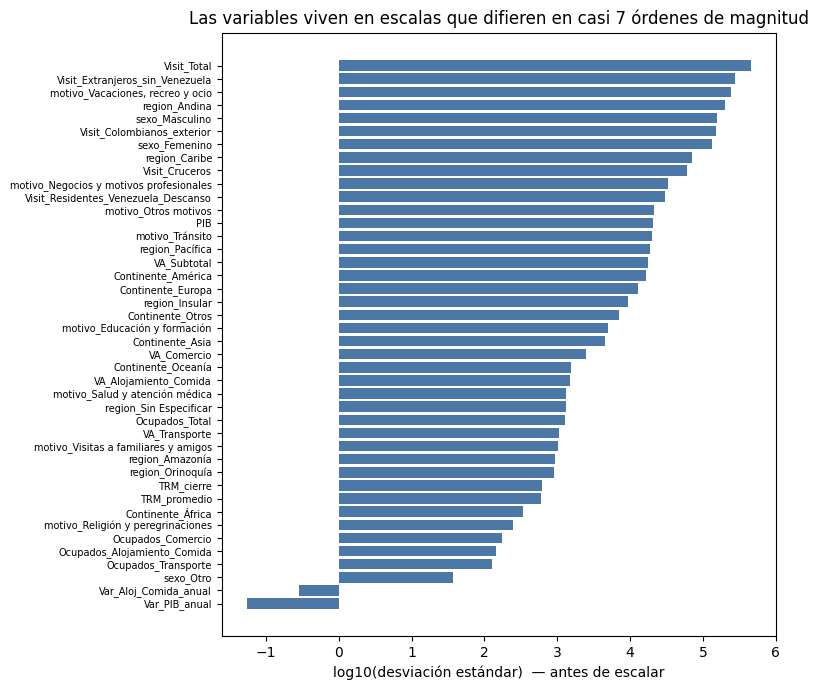

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))
orden = diag.sort_values("desv_est")
ax.barh(orden.index, np.log10(orden.desv_est.clip(lower=1e-3)), color="#4C78A8")
ax.set_xlabel("log10(desviación estándar)  — antes de escalar")
ax.set_title("Las variables viven en escalas que difieren en casi 7 órdenes de magnitud")
ax.tick_params(axis="y", labelsize=7); plt.tight_layout(); plt.show()

### Evaluación y Selección del Método de Escalado

Se analizan 4 alternativas metodológicas considerando el impacto del desplome del año 2020:

1. **Transformación Logarítmica (`log1p`):** Descartada. Al analizar la asimetría, el desplome del 2020 estira la cola hacia la izquierda en lugar de la derecha. El logaritmo empeora significativamente esta asimetría.
2. **Z-Score (Standardization):** Seleccionada para análisis de correlación, modelos lineales y algoritmos que asumen distribución normal.
3. **Robust Scaler (IQR):** Muy similar a Z-score en este dataset dado que la mediana y el IQR se mantienen relativamente estables frente al corto intervalo de la pandemia.
4. **Min-Max (Normalization):** Seleccionada para análisis visuales y comparación directa de variables en gráficos integrados (rango acotado entre 0 y 1).

In [ ]:
conteos = [c for c in num.columns if c.startswith(("region_","motivo_","sexo_","Continente_","Visit_"))]
asim = pd.DataFrame({
    "asimetria_original": num[conteos].apply(skew),
    "asimetria_log1p":   num[conteos].apply(lambda s: skew(np.log1p(s))),
})
asim["empeora"] = asim.asimetria_log1p.abs() > asim.asimetria_original.abs()
print(f"log1p empeora la asimetría en {asim.empeora.sum()} de {len(asim)} variables de conteo")
asim.round(2).sort_values("asimetria_log1p").head(8)

log1p empeora la asimetría en 24 de 29 variables de conteo


,asimetria_original,asimetria_log1p,empeora
motivo_Salud y atención médica,-1.17,-4.14,True
"motivo_Vacaciones, recreo y ocio",0.01,-4.08,True
region_Pacífica,-1.03,-4.01,True
motivo_Religión y peregrinaciones,4.04,-3.86,False
Continente_América,-2.04,-3.80,True
Continente_Otros,-1.14,-3.64,True
sexo_Femenino,-0.04,-3.42,True
Continente_Europa,-1.21,-3.40,True


Confirmamos que la transformación logarítmica perjudica la distribución en 24 de las 29 columnas principales de conteo, lo cual valida nuestra decisión de evitarla.


**Candidata 2 – Z-score (media 0, desviación 1).** Mantiene la forma de la serie (solo cambia origen y escala), deja los coeficientes de regresión comparables y es lo que esperan PCA y k-means. Su debilidad: media y desviación son sensibles al atípico del COVID.

**Candidata 3 – Escalado robusto (mediana e IQR).** Resiste atípicos, pero con solo 40 observaciones y un periodo COVID de 2-3 trimestres el IQR es estable y el resultado es casi el mismo que el z-score en el resto de la serie (se verifica abajo).

**Candidata 4 – Min-Max (0 a 1).** Ideal para **comparar visualmente** series en un mismo gráfico o construir índices, pero el mínimo y el máximo definen la escala, así que un atípico la deforma por completo.

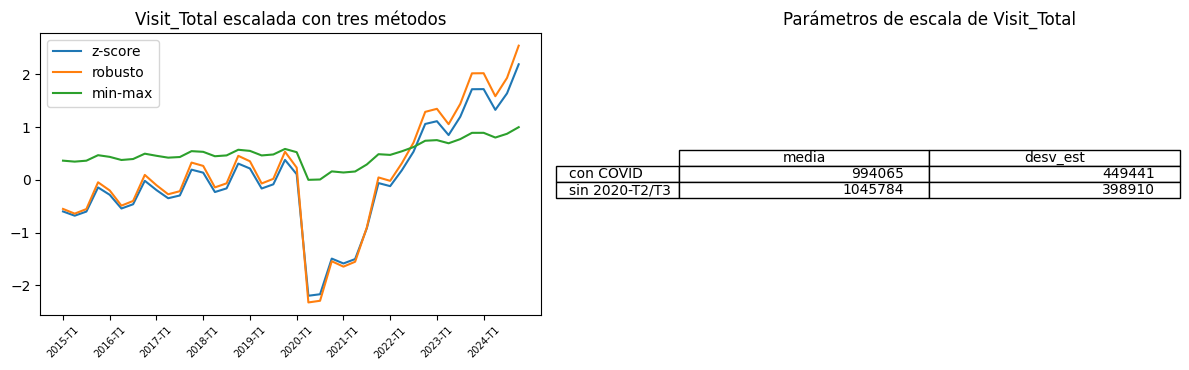

Corr. z-score vs robusto: 1.0000 (es la misma forma, cambia solo el origen/escala)


In [ ]:
def zscore(s):  return (s - s.mean()) / s.std(ddof=0)
def robusto(s): return (s - s.median()) / (s.quantile(.75) - s.quantile(.25))
def minmax(s):  return (s - s.min()) / (s.max() - s.min())

x = df["Visit_Total"]
t = df["Año"].astype(str) + "-T" + df["Trimestre"].astype(str)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for f, n in [(zscore,"z-score"), (robusto,"robusto"), (minmax,"min-max")]:
    ax[0].plot(t, f(x), label=n)
ax[0].set_title("Visit_Total escalada con tres métodos"); ax[0].legend()
ax[0].set_xticks(range(0, 40, 4)); ax[0].set_xticklabels(t[::4], rotation=45, fontsize=7)

sin_covid = ~((df.Año == 2020) & df.Trimestre.isin([2, 3]))
res = pd.DataFrame({"media": [x.mean(), x[sin_covid].mean()], "desv_est": [x.std(ddof=0), x[sin_covid].std(ddof=0)]},
                   index=["con COVID", "sin 2020-T2/T3"])
ax[1].axis("off"); ax[1].table(cellText=res.round(0).astype(int).values, rowLabels=res.index, colLabels=res.columns, loc="center")
ax[1].set_title("Parámetros de escala de Visit_Total")
plt.tight_layout(); plt.show()
print(f"Corr. z-score vs robusto: {np.corrcoef(zscore(x), robusto(x))[0,1]:.4f} (es la misma forma, cambia solo el origen/escala)")

## 7. Ingeniería de Variables: Participaciones por Grupos

Para facilitar la comparación del comportamiento relativo de los turistas sin importar el crecimiento absoluto en el volumen de visitantes, creamos **25 nuevas columnas** con las distribuciones de participación porcentual antes de proceder al escalado global.

### Nuevas Variables de Participación (%)

| Grupo | Columnas | Propósito Analítico |
|---|---|---|
| `Visit_Extranjeros_total` | 1 | Denominador unificado y correcto de las distribuciones |
| `part_region_*` | 7 | Distribución porcentual por región de destino |
| `part_motivo_*` | 8 | Estacionalidad de los motivos de viaje |
| `part_sexo_*` | 3 | Segmentación sociodemográfica |
| `part_continente_*` | 6 | Composición del origen geográfico de los turistas |

### 7.1 Unificación del Denominador de Extranjeros

A partir de 2020, las cifras oficiales del Ministerio de Comercio, Industria y Turismo (MinCIT) desagregan a los residentes de Venezuela que viajan por esparcimiento de la serie principal de extranjeros. Sin embargo, los reportes sectoriales (motivo, región, etc.) sí los incluyen en sus consolidados.

Para calcular participaciones correctas que sumen exactamente el 100%, definimos:
$$\text{Visit\_Extranjeros\_total} = \text{Visit\_Extranjeros\_sin\_Venezuela} + \text{Visit\_Residentes\_Venezuela\_Descanso}$$

In [ ]:
# 5.1 Total correcto de extranjeros no residentes
df["Visit_Extranjeros_total"] = (
    df["Visit_Extranjeros_sin_Venezuela"] + df["Visit_Residentes_Venezuela_Descanso"]
)

df[["Año", "Trimestre",
    "Visit_Extranjeros_sin_Venezuela",
    "Visit_Residentes_Venezuela_Descanso",
    "Visit_Extranjeros_total"]].iloc[[0, 19, 20, 39]]   # 2015-T1, 2019-T4, 2020-T1, 2024-T4

,Año,Trimestre,Visit_Extranjeros_sin_Venezuela,Visit_Residentes_Venezuela_Descanso,Visit_Extranjeros_total
0,2015,1,469954,0,469954
19,2019,4,700408,0,700408
20,2020,1,619891,90053,709944
39,2024,4,1115464,70401,1185865


### 7.2 Validación de Consistencia de los Denominadores

Evaluamos la precisión del denominador calculando el ratio de la suma de cada grupo de categorías frente al total estimado. Un valor exacto a **1** confirma consistencia lógica perfecta.

In [ ]:
# Validar el denominador con cada grupo de categorías
GRUPOS = ["region_", "motivo_", "sexo_", "Continente_"]

validacion = pd.DataFrame({
    g: df[[c for c in df.columns if c.startswith(g)]].sum(axis=1) / df["Visit_Extranjeros_total"]
    for g in GRUPOS
})

print("Suma de categorías / Visit_Extranjeros_total")
print(validacion.describe().loc[["min", "mean", "max"]].round(3))

# región, motivo y sexo deben cuadrar con el total (diferencias de unos pocos visitantes)
assert np.allclose(validacion[["region_", "motivo_", "sexo_"]], 1, atol=1e-3)

Suma de categorías / Visit_Extranjeros_total
      region_  motivo_  sexo_  Continente_
min       1.0      1.0    1.0        0.136
mean      1.0      1.0    1.0        0.261
max       1.0      1.0    1.0        1.137


### 7.3 Diagnóstico de Consistencia Geográfica

* **Resultados Robustos:** Las categorías de región, motivo y sexo cuadran al 100% con el total de extranjeros.
* **Caso Especial - Continentes:** Los datos de origen continental no cubren exactamente el mismo volumen total reportado por el ministerio.
* **Solución Analítica:** El grupo `part_continente_*` se calculará exclusivamente sobre la suma total reportada para ese grupo específico de continentes para evitar sesgos artificiales en los porcentajes.

### 7.4 Aplicación de las Transformaciones de Participación
Calculamos la representatividad de cada categoría dentro de su respectivo universo sobre la base original `df`:

In [ ]:
# 5.4 Crear las participaciones (%). Los conteos originales NO se modifican.
df_base = df.copy()

for g in GRUPOS:
    cols_grupo = [c for c in df.columns if c.startswith(g)]
    total_grupo = df[cols_grupo].sum(axis=1)           # suma de las categorías del grupo por trimestre
    for c in cols_grupo:
        nuevo = "part_" + c.replace("Continente_", "continente_")
        df_base[nuevo] = 100 * df[c] / total_grupo

cols_part = [c for c in df_base.columns if c.startswith("part_")]
print(f"Columnas de participación creadas: {len(cols_part)}")

df_base[["Año", "Trimestre", "region_Andina", "part_region_Andina"]].head(4)

Columnas de participación creadas: 24


,Año,Trimestre,region_Andina,part_region_Andina
0,2015,1,300140,63.865825
1,2015,2,309320,68.516545
2,2015,3,359632,69.001827
3,2015,4,363820,67.107508


In [ ]:
# 5.5 Verificación: dentro de cada irupo las participaciones deben sumar 100 %
for i in GRUPOS:
    prefijo = "part_" + i.lower()
    suma = df_base[[c for c in cols_part if c.startswith(prefijo)]].sum(axis=1)
    assert np.allclose(suma, 100), f"El irupo {i} no suma 100 %"
    print(f"{i:<12} -> {len([c for c in cols_part if c.startswith(prefijo)])} columnas, suman 100 % en los 40 trimestres")

print("\nColumnas nuevas en total:", 1 + len(cols_part), "| forma de la tabla:", df_base.shape)

region_      -> 7 columnas, suman 100 % en los 40 trimestres
motivo_      -> 8 columnas, suman 100 % en los 40 trimestres
sexo_        -> 3 columnas, suman 100 % en los 40 trimestres
Continente_  -> 6 columnas, suman 100 % en los 40 trimestres

Columnas nuevas en total: 25 | forma de la tabla: (40, 69)


### Resumen de Ingeniería de Variables

El dataset base ahora cuenta con **69 columnas** (44 originales y 25 nuevas).

In [ ]:
df = df_base
print(f"Total de columnas: {len(df.columns)}")

# Mostrar las columnas para verificar
print(len(df.columns))

Total de columnas: 69
69


## 8. Ejecución de la Normalización

Construimos y aplicamos de manera sistemática los dos enfoques de escalado seleccionados:

* **`df_z` (Z-score):** Para modelado estadístico, regresión y agrupación.
* **`df_mm` (Min-Max):** Para la visualización e integración gráfica de variables dispares.

*Nota: Las variables temporales `Año` y `Trimestre` quedan explícitamente excluidas del proceso de escalado para preservar el eje de tiempo intacto.*

### Replicabilidad y Diseño de Funciones

Para asegurar que este pipeline de preprocesamiento sea escalable e incorporable en procesos de producción ante nuevas actualizaciones de datos, la normalización se encapsula en una función parametrizable. Esta incluye control de divisiones por cero en columnas constantes y soporte para evitar el *data leakage* en fases posteriores de entrenamiento.

In [ ]:
# 6.1 Funciones de normalización y reversión
def normalizar_tabla(df, metodo="zscore", excluir=("Año", "Trimestre"), mask_ajuste=None):
    """
    Escala todas las columnas numéricas excepto las de 'excluir'.
    metodo: 'zscore' o 'minmax'.
    mask_ajuste: filas (booleano) con las que se calculan los parámetros; por defecto todas.
    Devuelve (tabla_normalizada, parametros).
    """
    cols = [c for c in df.select_dtypes("number").columns if c not in excluir]
    ref = df.loc[mask_ajuste, cols] if mask_ajuste is not None else df[cols]

    if metodo == "zscore":
        p = pd.DataFrame({"desplazamiento": ref.mean(), "escala": ref.std(ddof=0)})
    elif metodo == "minmax":
        p = pd.DataFrame({"desplazamiento": ref.min(), "escala": ref.max() - ref.min()})
    else:
        raise ValueError("metodo debe ser 'zscore' o 'minmax'")

    p["escala"] = p["escala"].replace(0, 1)       # columna constante: evita dividir entre 0
    p["metodo"] = metodo

    salida = df.copy()
    salida[cols] = (df[cols] - p["desplazamiento"]) / p["escala"]
    return salida, p


def desnormalizar(df_norm, params):
    """Revierte la normalización: devuelve los valores en su unidad original."""
    salida = df_norm.copy()
    salida[params.index] = df_norm[params.index] * params["escala"] + params["desplazamiento"]
    return salida

In [ ]:
# 6.2 Aplicar los dos métodos sobre df
df_z,  par_z  = normalizar_tabla(df, metodo="zscore")
df_mm, par_mm = normalizar_tabla(df, metodo="minmax")

print("df :", df.shape)
print("df_z    :", df_z.shape,  "| columnas escaladas:", len(par_z))
print("df_mm   :", df_mm.shape, "| columnas escaladas:", len(par_mm))

# Comparación de una misma variable en las tres versiones (2015-T1 y 2020-T2)
cols_demo = ["Visit_Total", "TRM_promedio", "PIB"]
comparacion = pd.concat({
    "original": df[cols_demo],
    "z-score":  df_z[cols_demo],
    "min-max":  df_mm[cols_demo],
}, axis=1).iloc[[0, 21]]
comparacion.round(3)

df : (40, 69)
df_z    : (40, 69) | columnas escaladas: 67
df_mm   : (40, 69) | columnas escaladas: 67


original                          z-score                      \
   Visit_Total TRM_promedio     PIB Visit_Total TRM_promedio    PIB   
0       724314      2474.60  191362      -0.600       -1.750 -1.473   
21        5003      3850.03  179599      -2.201        0.579 -2.045   

       min-max                      
   Visit_Total TRM_promedio    PIB  
0        0.364        0.000  0.137  
21       0.000        0.589  0.000

### Interpretación de Escalas

* **Z-score:** El valor $0$ representa la media del periodo. $+1$ indica una desviación estándar por encima del promedio, permitiendo detectar caídas extremas como la del 2020 ($~ -2.2$).
* **Min-Max:** Mapea el rango de la serie de tiempo entre $0$ (peor periodo histórico, 2020) y $1$ (periodo con mayor desempeño histórico).

## 9. Validación de la Normalización y Reversibilidad

Se realiza una serie de pruebas para garantizar el éxito del preprocesamiento:

| Prueba | Qué detecta | Objetivo |
|---|---|---|
| Z-score: promedio ≈ 0 | Centrado | Confirmar correcto desplazamiento de la media |
| Z-score: desviación ≈ 1 | Dispersión | Asegurar que la desviación sea unitaria |
| Min-Max: límites [0, 1] | Rango | Validar acotación del intervalo |
| Sin nulos generados | Integridad | Descartar divisiones por cero en constantes |
| Reversible | Consistencia | Demostrar que es posible recuperar el valor original exacto |
| Identificadores intactos | Aislamiento | Verificar que no se hayan modificado `Año` ni `Trimestre` |

In [ ]:
# 7. Validación
cols = par_z.index

pruebas = {
    "z-score: promedio ≈ 0":   np.allclose(df_z[cols].mean(), 0, atol=1e-9),
    "z-score: desviación ≈ 1": np.allclose(df_z[cols].std(ddof=0), 1),
    "min-max: mín=0 y máx=1":  np.allclose(df_mm[cols].min(), 0) and np.allclose(df_mm[cols].max(), 1),
    "sin valores faltantes":   df_z.isna().sum().sum() == 0 and df_mm.isna().sum().sum() == 0,
    "reversible":              np.allclose(desnormalizar(df_z,  par_z )[cols], df_base[cols]) and
                               np.allclose(desnormalizar(df_mm, par_mm)[cols], df_base[cols]),
    "identificadores intactos": df_z[["Año", "Trimestre"]].equals(df_base[["Año", "Trimestre"]]),
}

resultado = pd.Series(pruebas, name="cumple")
print(resultado)
assert resultado.all(), "Alguna validación falló"

z-score: promedio ≈ 0       True
z-score: desviación ≈ 1     True
min-max: mín=0 y máx=1      True
sin valores faltantes       True
reversible                  True
identificadores intactos    True
Name: cumple, dtype: bool


## 8. Validación de Resultados

Validamos el pipeline de normalización bajo pruebas estrictas de centrado, consistencia en rangos límite, control de nulos y reversibilidad exacta para garantizar que no haya pérdida de información en el proceso.

## 10. Análisis de Indicadores Clave de Rendimiento (KPI 1): Origen Geográfico

**Pregunta que responde (Pregunta 1).** ¿Cuál es la participación de cada continente de origen en el total de visitantes extranjeros no residentes, y cómo se relaciona la evolución de esa participación con el crecimiento trimestral del PIB?

| Elemento | Definición |
|---|---|
| **Definición** | Porcentaje de los visitantes extranjeros no residentes que proviene de cada continente, y correlación de esa participación con el crecimiento del PIB. |
| **Fórmula (participación)** | Por trimestre: `part_continente_c,t = Continente_c,t / Σ Continente_t × 100` (creada en la sección 7.4). Para todo el periodo (ponderada): `Σ_t Continente_c / Σ_t Σ_c Continente × 100`. |
| **Fórmula (relación con el PIB)** | Correlación de Pearson entre `part_continente_c` y `Var_PIB_anual` (variación del PIB frente al mismo trimestre del año anterior), con los 40 trimestres y sin 2020-T2/T3. |
| **Unidad** | Participación: % (puntos porcentuales, pp, para cambios). Correlación: coeficiente sin unidad, de −1 a 1. |
| **Periodicidad** | Trimestral; se recalcula al agregar cada trimestre nuevo a la base analítica. |
| **Interpretación** | Una participación alta indica dependencia de ese mercado emisor. Un cambio positivo en pp indica que el continente ganó peso. Una correlación positiva con `Var_PIB_anual` indica que el continente gana peso en trimestres de mayor crecimiento económico; negativa, lo contrario. |
| **Relevancia** | Orienta la promoción turística (a qué mercados dirigirse), mide la concentración de los mercados emisores y alerta sobre la dependencia de un solo origen, útil para FONTUR, gremios (ANATO, COTELCO) e inversionistas. |

**Variables que usa.** `part_continente_*`, `Continente_*` y `Var_PIB_anual`, de `df_base` (no de las tablas normalizadas, porque un KPI se lee en su unidad real).

**Limitaciones.** Los continentes no cubren el mismo universo que el total de extranjeros (sección 7.3), por eso la participación es sobre la suma de los continentes. 2020-T2/T3 se conservan; la correlación se muestra con y sin ellos. Correlación no es causalidad y con 40 observaciones es una señal exploratoria.

In [ ]:
# KPI 1.1 participación por continente (sobre df_base; no se modifica)
kpi1_part = [c for c in df_base.columns if c.startswith("part_continente_")]
kpi1_cont = ["Continente_" + c.replace("part_continente_", "") for c in kpi1_part]
assert kpi1_part, "No se encontraron columnas part_continente_*"

kpi1 = df_base[["Año", "Trimestre"] + kpi1_part].copy()
kpi1["Periodo"] = kpi1["Año"].astype(str) + "-T" + kpi1["Trimestre"].astype(str)
assert len(kpi1) == len(df_base), "Cambió el número de filas"
assert np.allclose(kpi1[kpi1_part].sum(axis=1), 100), "Las participaciones no suman 100 %"

kpi1_resumen = pd.DataFrame({
    "participación ponderada (%)": df_base[kpi1_cont].sum().values / df_base[kpi1_cont].sum().sum() * 100,
    "promedio trimestral (%)": kpi1[kpi1_part].mean().values,
    "mínimo (%)": kpi1[kpi1_part].min().values,
    "máximo (%)": kpi1[kpi1_part].max().values,
}, index=[c.replace("part_continente_", "") for c in kpi1_part]).sort_values("participación ponderada (%)", ascending=False)
kpi1_resumen.round(2)

,participación ponderada (%),promedio trimestral (%),mínimo (%),máximo (%)
América,42.29,41.87,24.27,47.98
Europa,27.68,27.15,22.31,33.12
Otros,18.22,19.90,13.75,49.79
Asia,8.66,8.16,2.60,11.69
Oceanía,2.59,2.37,0.11,3.61
África,0.57,0.55,0.20,0.86


### Cambio 2019 → 2024

**Qué hace.** Compara el promedio anual de participación de cada continente en 2019 (antes del COVID) y en 2024, en puntos porcentuales. **Por qué.** Muestra si la composición de los mercados emisores cambió después de la pandemia. **Qué concluimos.** Un valor positivo indica que el continente ganó peso; como el reparto suma 100 %, lo que gana uno lo pierden otros.

In [ ]:
# KPI 1.2 Cambio 2019 -> 2024
kpi1_anio = kpi1.groupby("Año")[kpi1_part].mean()
kpi1_cambio = pd.DataFrame({
    "2019 (%)": kpi1_anio.loc[2019],
    "2024 (%)": kpi1_anio.loc[2024],
})
kpi1_cambio["cambio (pp)"] = kpi1_cambio["2024 (%)"] - kpi1_cambio["2019 (%)"]
kpi1_cambio.index = kpi1_cambio.index.str.replace("part_continente_", "", regex=False)
kpi1_cambio.sort_values("2024 (%)", ascending=False).round(2)

,2019 (%),2024 (%),cambio (pp)
América,42.45,36.24,-6.22
Europa,29.07,29.99,0.92
Otros,16.98,19.86,2.88
Asia,8.28,10.40,2.12
Oceanía,2.74,2.79,0.05
África,0.49,0.73,0.24


### Gráfica: participación por continente

**Qué hace.** Muestra la participación (%) de cada continente por trimestre, apilada (suma 100 %). **Por qué.** Permite ver cómo evolucionó la composición del origen, incluido 2020. **Qué concluimos.** Ver la interpretación al final de la sección.

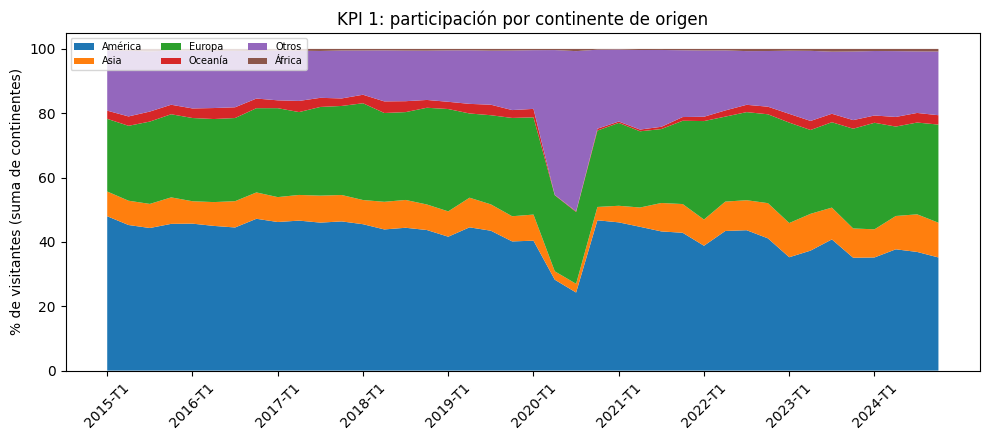

In [ ]:
# KPI 1.3 Gráfica
plt.figure(figsize=(10, 4.5))
plt.stackplot(range(len(kpi1)), [kpi1[c] for c in kpi1_part],
              labels=[c.replace("part_continente_", "") for c in kpi1_part])
plt.xticks(range(0, len(kpi1), 4), kpi1["Periodo"][::4], rotation=45)
plt.ylabel("% de visitantes (suma de continentes)")
plt.title("KPI 1: participación por continente de origen")
plt.legend(loc="upper left", fontsize=7, ncol=3)
plt.tight_layout(); plt.show()

### Interpretación del KPI 1 (Continentes)

- **Participación Dominante:** El continente americano lidera históricamente el volumen de visitas con una participación ponderada del **42.29%**, seguido por Europa con un **27.68%**.
- **Evolución 2019 vs 2024:** América registró una caída notable en su peso relativo, pasando de **42.45%** a **36.24%** (-6.22 pp). Por otro lado, el bloque de "Otros" continentes, Asia y Europa, ganaron terreno como mercados emisores de turistas.
- **Conclusiones Estratégicas:** Se evidencia una diversificación progresiva de los mercados emisores de turismo tras la pandemia, lo cual disminuye la dependencia de los flujos de la región americana y abre oportunidades para campañas focalizadas en Europa y Asia.

### Relación de la participación con el crecimiento del PIB

**Qué hace.** Calcula, para cada continente, la correlación entre su participación trimestral y `Var_PIB_anual`, con los 40 trimestres y sin 2020-T2/T3 (no se borra ninguna fila; solo se filtra para el cálculo). **Por qué.** Es la segunda parte de la Pregunta 1. **Qué concluimos.** Si el signo o la magnitud cambian mucho entre las dos columnas, la relación depende del COVID y no debe leerse como un patrón estable.

In [ ]:
# KPI 1 - Correlación participación por continente vs. crecimiento del PIB
kpi1_pib = df_base["Var_PIB_anual"]
kpi1_sin_covid = ~((df_base["Año"] == 2020) & df_base["Trimestre"].isin([2, 3]))

kpi1_corr = pd.DataFrame({
    "correlación (40 trimestres)": [kpi1[c].corr(kpi1_pib) for c in kpi1_part],
    "correlación (sin 2020-T2/T3)": [kpi1.loc[kpi1_sin_covid, c].corr(kpi1_pib[kpi1_sin_covid]) for c in kpi1_part],
}, index=[c.replace("part_continente_", "") for c in kpi1_part])
print(f"Trimestres usados sin COVID: {kpi1_sin_covid.sum()} de {len(kpi1)}")
kpi1_corr.round(2)

Trimestres usados sin COVID: 38 de 40


,correlación (40 trimestres),correlación (sin 2020-T2/T3)
América,0.48,0.06
Asia,0.42,-0.03
Europa,0.05,-0.26
Oceanía,0.06,-0.48
Otros,-0.50,0.33
África,-0.13,-0.28


**Interpretación de la relación con el PIB.** Con los 40 trimestres, las correlaciones son moderadas: positivas para América (0,48) y Asia (0,42) y negativa para "Otros" (-0,50). Al excluir 2020-T2/T3 casi todas se debilitan o cambian de signo: América baja a 0,06, Asia a -0,03 y "Otros" pasa a +0,33. Sin el COVID, ningún continente tiene una relación fuerte con el crecimiento del PIB; las más altas en valor absoluto son Oceanía (-0,48) y "Otros" (0,33), pero Oceanía pesa muy poco (menos del 3 %) y "Otros" es una categoría que agrupa orígenes distintos, así que ambas son poco confiables. Como el resultado depende de los dos trimestres de la pandemia, no hay evidencia de un patrón estable entre la composición del origen y el crecimiento económico. Es una señal exploratoria, con 38 observaciones y con la limitación de la base de continentes (sección 7.3).

In [ ]:
#Exportar
import os
os.makedirs("salidas", exist_ok=True)

df_base.to_csv("salidas/base_analitica.csv", index=False)
df_z.to_csv("salidas/base_normalizada_zscore.csv", index=False)
df_mm.to_csv("salidas/base_normalizada_minmax.csv", index=False)
pd.concat([par_z.assign(version="zscore"), par_mm.assign(version="minmax")]).to_csv("salidas/parametros_normalizacion.csv")



## 11. Análisis de Indicadores Clave de Rendimiento (KPI 2): Intensidad Turística del PIB

**Pregunta que resuelve (Pregunta 2, segunda parte).** *¿Qué relación existe, a nivel nacional, entre el total de visitantes recibidos y el PIB del país?*

| Elemento | Definición |
|---|---|
| **Definición** | Número de visitantes no residentes que recibe Colombia por cada mil millones de pesos de PIB en un trimestre. Indica si el turismo crece al mismo ritmo que la economía, más rápido o más lento. |
| **Fórmula** | `KPI = Visit_Total / PIB` |
| **Unidad** | Visitantes por cada mil millones de pesos de PIB. Ejemplo (2015-T1): 724.314 visitantes / 191.362 mil millones de pesos = 3,79. |
| **Periodicidad** | Trimestral; se recalcula al agregar cada trimestre nuevo a la base analítica. |
| **Interpretación** | Si el KPI sube, los visitantes crecen más rápido que la economía y el turismo gana peso relativo. Si baja, pierde peso. Si se mantiene constante, visitantes y PIB crecen en proporción. |
| **Relevancia** | Permite ver si el turismo receptor gana o pierde importancia frente al tamaño de la economía, útil para la planeación de la promoción turística y la inversión (FONTUR, gremios como ANATO y COTELCO) y para seguir la recuperación después de la pandemia. |

**Variables que usa.** `Visit_Total` (visitantes no residentes, en personas; fuente Migración Colombia a través de MinCIT) y `PIB` (PIB trimestral en miles de millones de pesos constantes; fuente DANE). Se calcula sobre `df_base` y no sobre las tablas normalizadas, porque un KPI se lee en su unidad real.

**Limitaciones.**
- `Visit_Total` incluye extranjeros, colombianos residentes en el exterior y pasajeros de cruceros; se usa el total porque la pregunta habla del "total de visitantes recibidos".
- El PIB es el de toda la economía, no solo el del turismo; por eso el KPI mide la *intensidad* del turismo frente a la economía, no el aporte del turismo al PIB.
- La correlación entre ambas series no demuestra causalidad.

In [ ]:

tabla = df_base[["Año", "Trimestre", "Visit_Total", "PIB"]].copy()


tabla["KPI"] = tabla["Visit_Total"] / tabla["PIB"]

# etiqueta de periodo (ejj 2015-T1), solo para las gráficas
tabla["Periodo"] = tabla["Año"].astype(str) + "-T" + tabla["Trimestre"].astype(str)

tabla.head()

,Año,Trimestre,Visit_Total,PIB,KPI,Periodo
0,2015,1,724314,191362,3.785046,2015-T1
1,2015,2,688063,196861,3.495172,2015-T2
2,2015,3,723272,203636,3.551788,2015-T3
3,2015,4,929267,212833,4.366179,2015-T4
4,2016,1,866186,195907,4.421414,2016-T1


In [ ]:
# Resumen del KPI
print("Promedio:", round(tabla["KPI"].mean(), 2))
print("Mínimo:", round(tabla["KPI"].min(), 2), "en", tabla.loc[tabla["KPI"].idxmin(), "Periodo"])
print("Máximo:", round(tabla["KPI"].max(), 2), "en", tabla.loc[tabla["KPI"].idxmax(), "Periodo"])

Promedio: 4.39
Mínimo: 0.03 en 2020-T2
Máximo: 7.49 en 2024-T1


In [ ]:
# Promedio de cada año
por_año = tabla.groupby("Año")[["Visit_Total", "PIB", "KPI"]].mean().round(2)
por_año

,Visit_Total,PIB,KPI
Año,,,
2015,766229.00,201173.00,3.80
2016,846800.75,205372.00,4.12
2017,921250.75,208164.25,4.42
2018,999750.25,213502.00,4.69
2019,1032690.50,220306.00,4.69
2020,346654.25,204475.00,1.63
2021,536452.75,226560.75,2.30
2022,1180414.00,243163.75,4.83
2023,1542553.75,244896.00,6.29


In [ ]:
# ¿Cuánto cambió cada cosa entre 2019 y 2024? (en %)
(por_año.loc[2024] / por_año.loc[2019] - 1) * 100

,0
Visit_Total,71.189480
PIB,12.938368
KPI,51.385928


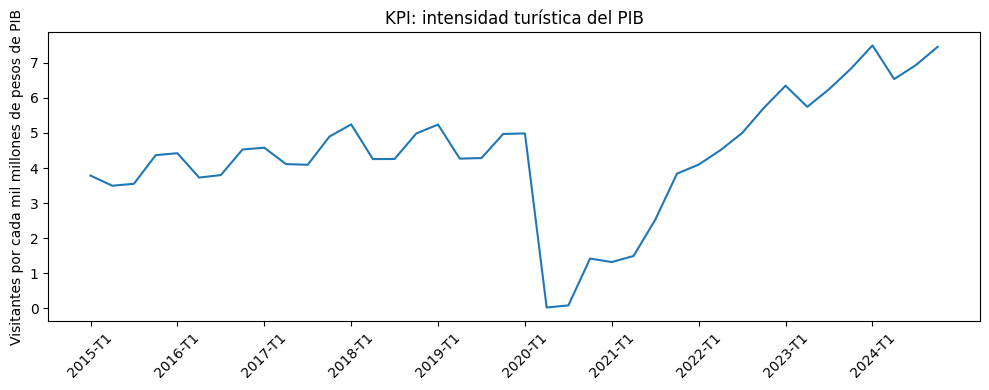

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(tabla["Periodo"], tabla["KPI"])
plt.xticks(range(0, len(tabla), 4), rotation=45)   # mostrar una etiqueta de cada 4
plt.ylabel("Visitantes por cada mil millones de pesos de PIB")
plt.title("KPI: intensidad turística del PIB")
plt.tight_layout()
plt.show()

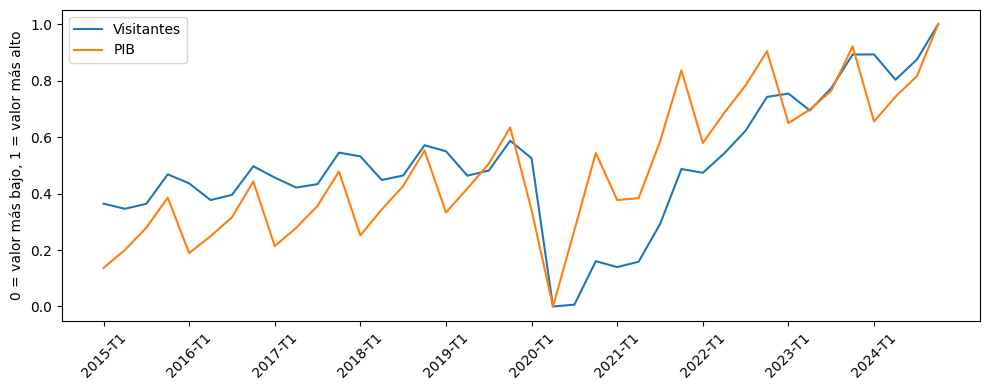

Correlación visitantes - PIB: 0.74


In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(tabla["Periodo"], df_mm["Visit_Total"], label="Visitantes")
plt.plot(tabla["Periodo"], df_mm["PIB"], label="PIB")
plt.xticks(range(0, len(tabla), 4), rotation=45)
plt.ylabel("0 = valor más bajo, 1 = valor más alto")
plt.legend()
plt.tight_layout()
plt.show()

# Qué tan relacionados están (1 = muy relacionados, 0 = nada)
print("Correlación visitantes - PIB:", round(tabla["Visit_Total"].corr(tabla["PIB"]), 2))

### KPI 2: Intensidad Turística sobre el PIB

#### Interpretación, Recuperación y Ciclicidad

- **Dinámica de Recuperación:** Tras el desplome del indicador en 2020 por las restricciones de movilidad, el KPI inició una recuperación a finales de 2021, superó los niveles previos a la pandemia durante 2022 y continuó subiendo hasta el final del periodo.
- **Impulsor del Crecimiento:** El aumento del KPI se debe a que los visitantes crecen mucho más rápido que el PIB: **+71,19 %** entre 2019 y 2024 frente a **+12,94 %** del PIB total. No se trata de un crecimiento exponencial sino de un rebote posterior al COVID que se desacelera: el crecimiento anual de los visitantes fue muy alto en 2022 y se fue moderando en 2023 y 2024. Esto indica que el turismo ganó relevancia relativa frente al tamaño de la economía.
- **Ciclo y Estacionalidad:** La serie muestra un patrón estacional recurrente. Los cuartos trimestres (T4) registran los valores más altos, asociados a las vacaciones de fin de año, a la llegada de colombianos residentes en el exterior y a la temporada alta de cruceros; el segundo trimestre es el más bajo.
- **Relación con el PIB:** La correlación entre visitantes y PIB es positiva y alta (0,74), pero no demuestra causalidad: ambas series crecen con el tiempo y el PIB depende de muchos otros factores.

## 12. Análisis de Indicadores Clave de Rendimiento (KPI 3): Estacionalidad de los Motivos de Viaje

**Pregunta que responde (Pregunta 4).** ¿Existen patrones estacionales en los motivos de viaje de los visitantes (vacaciones, negocios, salud, tránsito, etc.), y cómo se relacionan con las variaciones trimestrales del PIB de alojamiento y servicios de comida?

| Elemento | Definición |
|---|---|
| **Definición** | Índice que mide cuánto pesa cada motivo de viaje en cada trimestre del año (T1 a T4) frente a su peso típico, y relación de esa composición con la variación del PIB de alojamiento y servicios de comida. |
| **Fórmula (índice estacional)** | `IE_m,q = promedio de part_motivo_m en el trimestre q / promedio de part_motivo_m en los 4 trimestres × 100`, con años de referencia 2015-2019. |
| **Fórmula (amplitud)** | `amplitud_m = máx(IE_m,q) − mín(IE_m,q)`. |
| **Fórmula (relación con el sector)** | Correlación de Pearson entre `part_motivo_m` y `Var_Aloj_Comida_anual` (variación del PIB de alojamiento y comida frente al mismo trimestre del año anterior), con los 40 trimestres y sin 2020-T2/T3. |
| **Unidad** | Índice base 100 (100 = peso típico del motivo; 120 = 20 % por encima). Amplitud en puntos de índice. Correlación sin unidad, de −1 a 1. |
| **Periodicidad** | Trimestral; se recalcula al agregar cada trimestre nuevo a la base analítica. |
| **Interpretación** | Un `IE` > 100 en un trimestre indica que el motivo es proporcionalmente más frecuente en ese trimestre (su temporada alta); una amplitud grande indica un motivo muy estacional. Si el trimestre pico de los motivos coincide con el del valor agregado de alojamiento y comida, la demanda turística y la actividad del sector se mueven juntas. |
| **Relevancia** | Permite a hoteles, restaurantes y entidades de promoción (FONTUR, gremios como COTELCO y ANATO) planear oferta, personal y campañas según el motivo que domina cada temporada, y reconocer qué segmentos (negocios, salud, tránsito) sostienen la demanda cuando baja la temporada de vacaciones. |

**Variables que usa.** `part_motivo_*` (sección 7, fuente MinCIT), `Var_Aloj_Comida_anual` y `VA_Alojamiento_Comida` (DANE), todas de `df_base`. Se calcula sobre `df_base` y no sobre las tablas normalizadas, porque un KPI se lee en su unidad real.

**Limitaciones.**
- Se usa la **participación** de cada motivo (composición), no el volumen: un motivo puede tener más peso en un trimestre aunque lleguen menos visitantes en total.
- **Años de referencia 2015-2019** (parámetro `ANIOS_REF`): son los únicos con un patrón anual estable; 2020 rompe el ciclo y 2022-2023 seguían en recuperación. 2020-T2/T3 **se conservan** en `df_base`; solo se dejan fuera del cálculo del índice y se muestran con y sin esos trimestres en la correlación.
- `Var_Aloj_Comida_anual` compara cada trimestre con el mismo trimestre del año anterior, así que **ya descuenta la estacionalidad**: su correlación con la participación de un motivo indica si los cambios de composición acompañan el crecimiento del sector, no si comparten estación. Para comparar estaciones se usa el índice del valor agregado (`VA_Alojamiento_Comida`).
- Motivos con peso muy pequeño (p. ej. religión) tienen índices más inestables; la tabla incluye su peso promedio para leerlos con cautela.
- Correlación no es causalidad, y con 40 observaciones es una señal exploratoria.

In [ ]:
#KPI 3: índice estacional de los motivos de viaje (sobre df_base; no se modifica)
ANIOS_REF = range(2015, 2020)          # años de referencia (pre-COVID);

kpi3_part = [c for c in df_base.columns if c.startswith("part_motivo_")]
assert kpi3_part, "No se encontraron columnas part_motivo_*"
for c in ["Var_Aloj_Comida_anual", "VA_Alojamiento_Comida"]:
    assert c in df_base.columns, f"Falta la columna {c}"

kpi3 = df_base[["Año", "Trimestre", "Var_Aloj_Comida_anual", "VA_Alojamiento_Comida"] + kpi3_part].copy()
kpi3["Periodo"] = kpi3["Año"].astype(str) + "-T" + kpi3["Trimestre"].astype(str)
assert len(kpi3) == len(df_base), "Cambió el número de filas"

ref = kpi3[kpi3["Año"].isin(ANIOS_REF)]
prom_q = ref.groupby("Trimestre")[kpi3_part].mean()                 # promedio por trimestre calendario
kpi3_ie = prom_q / prom_q.mean() * 100                              # índice base 100
kpi3_ie.columns = [c.replace("part_motivo_", "") for c in kpi3_part]

# Referencia del sector: índice estacional del valor agregado de alojamiento y comida
va_rel = ref["VA_Alojamiento_Comida"] / ref.groupby("Año")["VA_Alojamiento_Comida"].transform("mean")
kpi3_ie_sector = va_rel.groupby(ref["Trimestre"]).mean() * 100

kpi3_resumen = pd.DataFrame({
    "peso promedio (%)": kpi3[kpi3_part].mean().values,
    "trimestre pico": ["T" + str(int(kpi3_ie[c].idxmax())) for c in kpi3_ie.columns],
    "trimestre valle": ["T" + str(int(kpi3_ie[c].idxmin())) for c in kpi3_ie.columns],
    "amplitud (puntos)": (kpi3_ie.max() - kpi3_ie.min()).values,
}, index=kpi3_ie.columns).sort_values("amplitud (puntos)", ascending=False)

print(f"Años de referencia: {min(ANIOS_REF)}-{max(ANIOS_REF)}")
print("Trimestre pico del valor agregado de alojamiento y comida: T" + str(int(kpi3_ie_sector.idxmax())))
print("\nÍndice estacional por motivo (100 = peso típico):")
print(kpi3_ie.round(1).to_string())
kpi3_resumen.round(2)

Años de referencia: 2015-2019
Trimestre pico del valor agregado de alojamiento y comida: T4

Índice estacional por motivo (100 = peso típico):
           Educación y formación  Negocios y motivos profesionales  Otros motivos  Religión y peregrinaciones  Salud y atención médica  Tránsito  Vacaciones, recreo y ocio  Visitas a familiares y amigos
Trimestre                                                                                                                                                                                                 
1                           77.3                              95.1           99.4                       117.5                     93.9     111.3                      101.8                           71.5
2                          101.6                             111.7          102.5                        79.6                    108.1      93.7                       97.1                           92.0
3                          122.5             

,peso promedio (%),trimestre pico,trimestre valle,amplitud (puntos)
Religión y peregrinaciones,0.07,T3,T4,72.30
Visitas a familiares y amigos,0.25,T4,T1,55.88
Educación y formación,1.61,T3,T1,45.22
Negocios y motivos profesionales,11.57,T2,T4,20.22
Tránsito,2.30,T1,T4,19.39
Salud y atención médica,0.75,T2,T1,14.19
Otros motivos,10.29,T2,T3,6.13
"Vacaciones, recreo y ocio",73.16,T4,T2,4.85


### Gráfica: patrón estacional de los motivos principales

**Qué hace.** Dibuja el índice estacional (T1 a T4) de los 4 motivos con mayor peso promedio, junto con el del valor agregado de alojamiento y comida (línea negra punteada). **Por qué.** Permite ver de un vistazo en qué trimestre domina cada motivo y si coincide con el pico del sector. **Qué concluimos.**

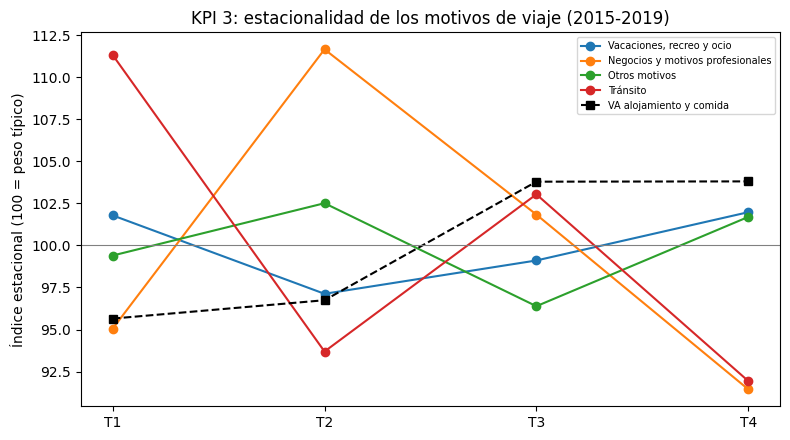

In [ ]:
# 12.2 Gráfica del índice estacional
kpi3_top = kpi3_resumen["peso promedio (%)"].nlargest(4).index.tolist()
plt.figure(figsize=(8, 4.5))
for m in kpi3_top:
    plt.plot(["T1", "T2", "T3", "T4"], kpi3_ie[m].values, marker="o", label=m)
plt.plot(["T1", "T2", "T3", "T4"], kpi3_ie_sector.values, "k--", marker="s", label="VA alojamiento y comida")
plt.axhline(100, color="gray", lw=0.8)
plt.ylabel("Índice estacional (100 = peso típico)")
plt.title("KPI 3: estacionalidad de los motivos de viaje (2015-2019)")
plt.legend(fontsize=7); plt.tight_layout(); plt.show()

### Relación con el PIB de alojamiento y servicios de comida

**Qué hace.** Calcula, para cada motivo, la correlación entre su participación trimestral y `Var_Aloj_Comida_anual`, con los 40 trimestres y sin 2020-T2/T3 (no se borra ninguna fila; solo se filtra para el cálculo). **Por qué.** Es la parte de la pregunta que pide relacionar los motivos de viaje con las variaciones del PIB del sector. **Qué concluimos.** Si el signo o la magnitud cambian mucho entre las dos columnas, la relación depende del COVID y no debe leerse como un patrón estable.

In [ ]:
# 12.3 Correlación participación del motivo vs. variación anual del PIB de alojamiento y comida
kpi3_sin_covid = ~((kpi3["Año"] == 2020) & kpi3["Trimestre"].isin([2, 3]))

kpi3_corr = pd.DataFrame({
    "correlación (40 trimestres)": [kpi3[c].corr(kpi3["Var_Aloj_Comida_anual"]) for c in kpi3_part],
    "correlación (sin 2020-T2/T3)": [kpi3.loc[kpi3_sin_covid, c].corr(kpi3.loc[kpi3_sin_covid, "Var_Aloj_Comida_anual"]) for c in kpi3_part],
}, index=[c.replace("part_motivo_", "") for c in kpi3_part])
print(f"Trimestres usados sin COVID: {kpi3_sin_covid.sum()} de {len(kpi3)}")
kpi3_corr.sort_values("correlación (sin 2020-T2/T3)", ascending=False).round(2)

Trimestres usados sin COVID: 38 de 40


,correlación (40 trimestres),correlación (sin 2020-T2/T3)
Otros motivos,-0.42,0.61
Visitas a familiares y amigos,0.02,0.58
Salud y atención médica,0.15,0.51
Tránsito,0.23,0.18
Religión y peregrinaciones,0.09,0.10
"Vacaciones, recreo y ocio",0.45,-0.04
Negocios y motivos profesionales,-0.23,-0.22
Educación y formación,-0.08,-0.24


### Interpretación del KPI 3 (Motivos de viaje)



- **Patrón estacional (12.1 y gráfica).** Qué motivos tienen mayor amplitud y en qué trimestre alcanzan su pico; típicamente se esperan picos de vacaciones y visitas a familiares en los trimestres de temporada alta, y motivos como negocios o salud más estables.
- **Coincidencia con el sector.** Comparar el trimestre pico de cada motivo con el del valor agregado de alojamiento y comida (impreso en 12.1): si coinciden, la demanda y el sector se mueven juntos en el año.
- **Relación con el PIB del sector (12.3).** Qué motivos tienen correlación positiva o negativa con `Var_Aloj_Comida_anual`; comparar las dos columnas para saber si el resultado lo explica el COVID.
- **Conclusión para el observatorio.** En una o dos frases, qué motivos sostienen la demanda en cada temporada y cuáles conviene monitorear.

## 13. Análisis de Indicadores Clave de Rendimiento (KPI 4): Distribución por Región de Destino

**Pregunta que responde (Pregunta 2, primera parte).** ¿Cómo se distribuyen los visitantes extranjeros no residentes de Colombia según la región de destino? (La relación entre visitantes y PIB, segunda parte de la pregunta, la responde el KPI 2.)

| Elemento | Definición |
|---|---|
| **Definición** | Porcentaje de los visitantes extranjeros no residentes que tiene como destino cada región del país. |
| **Fórmula** | `part_region_r,t = region_r,t / Σ region_t × 100` (creada en la sección 7.4). Para todo el periodo (ponderada): `Σ_t region_r / Σ_t Σ_r region × 100`. |
| **Unidad** | % (puntos porcentuales, pp, para cambios entre periodos). |
| **Periodicidad** | Trimestral; se recalcula al agregar cada trimestre nuevo a la base analítica. |
| **Interpretación** | Una región con participación alta concentra el turismo extranjero; si el reparto es parejo, el turismo está descentralizado. Un cambio positivo en pp indica que la región ganó peso. |
| **Relevancia** | Muestra dónde se concentra la demanda extranjera, orienta la inversión en infraestructura y promoción regional (FONTUR, gobernaciones, gremios) y permite seguir si el turismo se desconcentra de la región líder. |

**Variables que usa.** `part_region_*` y `region_*` de `df_base` (fuente MinCIT). Estas participaciones son las más sólidas de la tabla: la suma de las regiones cuadra con el total de extranjeros (sección 7.2).

**Limitaciones.** `region_Sin Especificar` tenía un valor faltante que se completó por diferencia (sección 4); su peso es el de visitantes cuyo destino no se reportó. 2020-T2/T3 se conservan; con tan pocos visitantes las participaciones de esos trimestres son más inestables.

In [ ]:
# KPI 4.1 Participación por región de destino (sobre df_base; no se modifica)
kpi4_part = [c for c in df_base.columns if c.startswith("part_region_")]
kpi4_reg = ["region_" + c.replace("part_region_", "") for c in kpi4_part]
assert kpi4_part, "No se encontraron columnas part_region_*"

kpi4 = df_base[["Año", "Trimestre"] + kpi4_part].copy()
kpi4["Periodo"] = kpi4["Año"].astype(str) + "-T" + kpi4["Trimestre"].astype(str)
assert len(kpi4) == len(df_base), "Cambió el número de filas"
assert np.allclose(kpi4[kpi4_part].sum(axis=1), 100), "Las participaciones no suman 100 %"

kpi4_resumen = pd.DataFrame({
    "participación ponderada (%)": df_base[kpi4_reg].sum().values / df_base[kpi4_reg].sum().sum() * 100,
    "promedio trimestral (%)": kpi4[kpi4_part].mean().values,
    "mínimo (%)": kpi4[kpi4_part].min().values,
    "máximo (%)": kpi4[kpi4_part].max().values,
}, index=[c.replace("part_region_", "") for c in kpi4_part]).sort_values("participación ponderada (%)", ascending=False)
kpi4_resumen.round(2)

,participación ponderada (%),promedio trimestral (%),mínimo (%),máximo (%)
Andina,66.78,67.30,61.49,86.69
Caribe,21.75,20.80,8.68,25.99
Pacífica,7.80,8.22,3.57,14.87
Insular,3.00,2.98,0.04,6.40
Amazonía,0.29,0.30,0.17,0.65
Orinoquía,0.28,0.30,0.20,0.71
Sin Especificar,0.10,0.10,0.00,0.67


### Cambio 2019 → 2024

**Qué hace.** Compara el promedio anual de participación de cada región en 2019 (antes del COVID) y 2024, en puntos porcentuales. **Por qué.** Muestra si el turismo se concentró o se repartió más después de la pandemia. **Qué concluimos.** Un valor positivo indica que la región ganó peso; como el reparto suma 100 %, lo que gana una lo pierden otras.

In [ ]:
# KPI 4.2 Cambio 2019 -> 2024
kpi4_anio = kpi4.groupby("Año")[kpi4_part].mean()
kpi4_cambio = pd.DataFrame({"2019 (%)": kpi4_anio.loc[2019], "2024 (%)": kpi4_anio.loc[2024]})
kpi4_cambio["cambio (pp)"] = kpi4_cambio["2024 (%)"] - kpi4_cambio["2019 (%)"]
kpi4_cambio.index = kpi4_cambio.index.str.replace("part_region_", "", regex=False)
kpi4_cambio.sort_values("2024 (%)", ascending=False).round(2)

,2019 (%),2024 (%),cambio (pp)
Andina,64.97,67.96,2.99
Caribe,22.53,23.18,0.65
Pacífica,7.86,6.28,-1.58
Insular,3.50,2.00,-1.50
Amazonía,0.37,0.29,-0.08
Orinoquía,0.22,0.26,0.05
Sin Especificar,0.56,0.04,-0.52


### Gráfica: participación por región de destino

**Qué hace.** Muestra la participación (%) de cada región por trimestre, apilada (suma 100 %). **Por qué.** Permite ver si la composición del destino es estable o cambia por tramos, incluido 2020. **Qué concluimos.** Ver la interpretación al final de la sección.

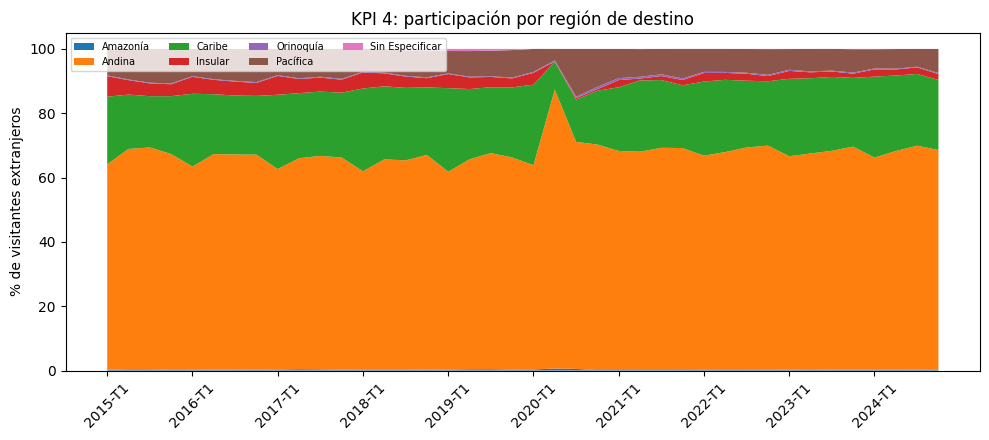

In [ ]:
# KPI 4.3 Gráfica
plt.figure(figsize=(10, 4.5))
plt.stackplot(range(len(kpi4)), [kpi4[c] for c in kpi4_part],
              labels=[c.replace("part_region_", "") for c in kpi4_part])
plt.xticks(range(0, len(kpi4), 4), kpi4["Periodo"][::4], rotation=45)
plt.ylabel("% de visitantes extranjeros")
plt.title("KPI 4: participación por región de destino")
plt.legend(loc="upper left", fontsize=7, ncol=4)
plt.tight_layout(); plt.show()

### Interpretación del KPI 4 (Regiones)

- **Concentración.** La región Andina lidera de forma clara: concentra cerca del 67 % de los visitantes extranjeros en la columna ponderada. Junto con el Caribe (cerca del 22 %) suman alrededor del 89 %. Como la Andina supera la mitad, el turismo extranjero depende de una sola región. El Pacífico (cerca del 8 %) y la región Insular (3 %) pesan poco, y Amazonía y Orinoquía menos del 0,3 % cada una.
- **Cambio 2019 → 2024.** El turismo no se desconcentró después de la pandemia: la Andina ganó cerca de 3 puntos porcentuales (de 64,97 % a 67,96 %) y el Caribe 0,65, mientras el Pacífico (-1,58) y la región Insular (-1,50) perdieron peso. El pico de 86,7 % de la Andina en 2020-T2 corresponde a un trimestre con muy pocos visitantes y no representa una concentración real.
- **Sin especificar.** Su peso es mínimo (cerca del 0,1 %) y baja de 0,56 % en 2019 a 0,04 % en 2024, lo que sugiere que el destino se está registrando mejor. Esto último es una hipótesis que habría que confirmar con la fuente.
- **Conclusión para el observatorio.** La demanda extranjera sigue concentrada en la Andina y el Caribe. Las regiones con margen de crecimiento son el Pacífico y las de menor peso, que no han ganado participación en los últimos años.

## 14. Análisis de Indicadores Clave de Rendimiento (KPI 5): Sensibilidad del Flujo Turístico a la TRM

**Pregunta que responde (Pregunta 3).** ¿Cómo influye la variación de la TRM en el flujo de turistas internacionales, y este efecto varía según el origen?

| Elemento | Definición |
|---|---|
| **Definición** | Correlación entre la variación anual de la TRM y la variación anual de los visitantes extranjeros no residentes (total y por continente de origen), con rezago de 0 y 1 trimestre. |
| **Fórmula** | `var_x,t = (x_t / x_(t−4) − 1) × 100`, para `x` = TRM promedio, visitantes extranjeros totales y visitantes por continente. KPI = correlación de Pearson entre `var_TRM,(t−k)` y `var_visitantes,t`, con `k` = 0 y 1. |
| **Unidad** | Variaciones en %; la correlación es un coeficiente sin unidad, de −1 a 1. |
| **Periodicidad** | Trimestral; se recalcula al agregar cada trimestre nuevo a la base analítica. |
| **Interpretación** | Correlación positiva: cuando la TRM sube (peso más débil frente al dólar, Colombia más barata para quien trae dólares) el flujo también crece. Cercana a 0: la TRM no explica el flujo. El rezago 1 mide si el efecto aparece un trimestre después. Comparar continentes muestra si el efecto varía según el origen. |
| **Relevancia** | Indica si el tipo de cambio es una variable a monitorear para anticipar la demanda internacional, útil para operadores turísticos, aerolíneas y entidades de promoción en la planeación de campañas y precios. |

**Variables que usa.** `TRM_promedio`, `Visit_Extranjeros_total` y `Continente_*` de `df_base`. Las variaciones se calculan en una tabla aparte (`kpi5`) para no modificar `df_base` ni borrar filas; los primeros 4 trimestres no tienen variación anual y se omiten solo en el cálculo.

**Limitaciones.**
- **La tabla solo tiene continentes, no países.** La parte "según el país de origen" se responde a nivel de continente.
- La TRM es el peso frente al dólar; para visitantes de otras monedas (por ejemplo, Europa) es solo una aproximación.
- Las variaciones anuales de 2020 y 2021 (caída por COVID y rebote desde una base muy baja) dominan el resultado; por eso se muestra también el cálculo **sin 2020 y 2021** (solo en el cálculo, las filas se conservan).
- Correlación no es causalidad, y el efecto del tipo de cambio puede mezclarse con otros factores (conectividad aérea, seguridad, ciclo económico del país de origen).

In [ ]:
# KPI 5.1 Variaciones anuales de TRM y visitantes (tabla aparte; df_base no se modifica)
kpi5_cont = [c for c in df_base.columns if c.startswith("Continente_")]
kpi5_flujo = ["Visit_Extranjeros_total"] + kpi5_cont
for c in ["TRM_promedio", "Visit_Extranjeros_total"]:
    assert c in df_base.columns, f"Falta la columna {c}"
assert df_base[["Año", "Trimestre"]].equals(df_base.sort_values(["Año", "Trimestre"])[["Año", "Trimestre"]]), \
    "La tabla debe estar ordenada por Año y Trimestre"

kpi5 = df_base[["Año", "Trimestre"]].copy()
kpi5["Periodo"] = kpi5["Año"].astype(str) + "-T" + kpi5["Trimestre"].astype(str)
kpi5_yoy = (df_base[["TRM_promedio"] + kpi5_flujo].pct_change(4) * 100).replace([np.inf, -np.inf], np.nan)
assert len(kpi5_yoy) == len(df_base), "Cambió el número de filas"

kpi5_etiquetas = ["Total extranjeros"] + [c.replace("Continente_", "") for c in kpi5_cont]
kpi5_sin_covid = ~kpi5["Año"].isin([2020, 2021])      # solo para el cálculo; no se borra nada

def kpi5_correlaciones(mascara, rezago):
    x = kpi5_yoy["TRM_promedio"].shift(rezago)
    return [x[mascara].corr(kpi5_yoy[c][mascara]) for c in kpi5_flujo]

kpi5_corr = pd.DataFrame({
    "rezago 0 (todo)": kpi5_correlaciones(pd.Series(True, index=kpi5.index), 0),
    "rezago 1 (todo)": kpi5_correlaciones(pd.Series(True, index=kpi5.index), 1),
    "rezago 0 (sin 2020-21)": kpi5_correlaciones(kpi5_sin_covid, 0),
    "rezago 1 (sin 2020-21)": kpi5_correlaciones(kpi5_sin_covid, 1),
}, index=kpi5_etiquetas)

n_todo = kpi5_yoy[["TRM_promedio", "Visit_Extranjeros_total"]].dropna().shape[0]
n_sin = kpi5_yoy.loc[kpi5_sin_covid, ["TRM_promedio", "Visit_Extranjeros_total"]].dropna().shape[0]
print(f"Observaciones usadas (total extranjeros): {n_todo} con todo el periodo, {n_sin} sin 2020-2021")
kpi5_corr.round(2)

Observaciones usadas (total extranjeros): 36 con todo el periodo, 28 sin 2020-2021


,rezago 0 (todo),rezago 1 (todo),rezago 0 (sin 2020-21),rezago 1 (sin 2020-21)
Total extranjeros,-0.14,-0.13,0.20,0.16
América,-0.14,-0.12,0.27,0.18
Asia,-0.13,-0.13,0.28,0.25
Europa,-0.14,-0.12,0.28,0.16
Oceanía,-0.13,-0.09,0.28,0.21
Otros,-0.14,-0.11,0.23,0.27
África,-0.10,-0.08,0.26,0.14


### Gráfica: TRM vs. flujo de visitantes

**Qué hace.** Dispersión de la variación anual de la TRM contra la variación anual de los visitantes extranjeros, sin 2020 y 2021, con su recta de tendencia. **Por qué.** Permite ver la relación sin que el COVID domine la escala. **Qué concluimos.** Ver la interpretación al final de la sección.

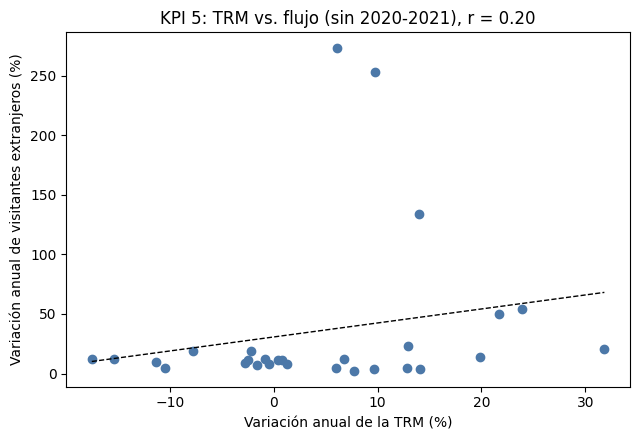

In [ ]:
# KPI 5.2 Dispersión TRM vs. visitantes (sin 2020-2021)
kpi5_xy = pd.DataFrame({"trm": kpi5_yoy["TRM_promedio"], "vis": kpi5_yoy["Visit_Extranjeros_total"]})[kpi5_sin_covid].dropna()
plt.figure(figsize=(6.5, 4.5))
plt.scatter(kpi5_xy["trm"], kpi5_xy["vis"], color="#4C78A8")
pend, inter = np.polyfit(kpi5_xy["trm"], kpi5_xy["vis"], 1)
xs = np.linspace(kpi5_xy["trm"].min(), kpi5_xy["trm"].max(), 50)
plt.plot(xs, pend * xs + inter, "k--", lw=1)
plt.xlabel("Variación anual de la TRM (%)"); plt.ylabel("Variación anual de visitantes extranjeros (%)")
plt.title(f"KPI 5: TRM vs. flujo (sin 2020-2021), r = {kpi5_xy['trm'].corr(kpi5_xy['vis']):.2f}")
plt.tight_layout(); plt.show()

### Interpretación del KPI 5 (TRM)


- **Efecto general.** Signo y tamaño de la correlación del total de extranjeros; comparar con y sin 2020-2021 para saber si el COVID explica el resultado.
- **Rezago.** Si la correlación con rezago 1 es mayor que con rezago 0, el efecto de la TRM tarda un trimestre en reflejarse.
- **Por origen.** Qué continentes responden más (|r| más alto) y cuáles no responden; recordar que la tabla no tiene países.
- **Conclusión para el observatorio.** En una o dos frases, si la TRM sirve como señal para anticipar el flujo y para qué orígenes.